In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [36]:
df_julio_domestico = pd.read_csv(
    "planillas/julio_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_agosto_domestico = pd.read_csv(
    "planillas/agosto_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_septiembre_domestico = pd.read_csv(
    "planillas/septiembre_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_octubre_domestico = pd.read_csv(
    "planillas/octubre_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)

In [37]:
df_julio_domestico['PAGO?'] = df_julio_domestico['PAGO?'].fillna('')
df_agosto_domestico['PAGO?'] = df_agosto_domestico['PAGO?'].fillna('')
df_septiembre_domestico['PAGO?'] = df_septiembre_domestico['PAGO?'].fillna('')
df_octubre_domestico['PAGO?'] = df_octubre_domestico['PAGO?'].fillna('')

In [38]:
def excluir_nombres(df):
    nombres_excluir = ["CIDAL", "LAVANDERIA", "GIMNASIO"]
    df = df[
        ~df["NOMBRE Y APELLIDO"].str.contains(
            "|".join(nombres_excluir),
            case=False,
            na=False
        )
    ]
    return df

def pagado_vs_porpagar(df):
    #Lo que se deberia pagar sin CIDAL ni espacios comunes como lavanderia ni gimnacio
    total_a_pagar = round(df["TOTAL"].sum(), 2)
    total_pagado = 0
    for indice, fila in df.iterrows():
        if fila["PAGO?"].strip() == "S" or fila["PAGO?"].strip() == "s":
            total_pagado += round(fila["TOTAL"], 2)
        else:
            pago_str = str(fila["PAGO?"]).strip()
            if len(pago_str) > 0:
                pago_str = pago_str.replace(",", ".")
                total_pagado += round(float(pago_str), 2)
    return round(total_a_pagar, 2), round(total_pagado, 2)

In [39]:
df_julio_domestico = excluir_nombres(df_julio_domestico)
df_agosto_domestico = excluir_nombres(df_agosto_domestico)
df_septiembre_domestico = excluir_nombres(df_septiembre_domestico)
df_octubre_domestico = excluir_nombres(df_octubre_domestico)

total_a_pagar_julio, total_pagado_julio = pagado_vs_porpagar(df_julio_domestico)
total_a_pagar_agosto, total_pagado_agosto = pagado_vs_porpagar(df_agosto_domestico)
total_a_pagar_septiembre, total_pagado_septiembre = pagado_vs_porpagar(df_septiembre_domestico)
total_a_pagar_octubre, total_pagado_octubre = pagado_vs_porpagar(df_octubre_domestico)

df_apagar_vs_pagado = pd.DataFrame({
    "TOTAL A PAGAR": [total_a_pagar_julio, total_a_pagar_agosto, total_a_pagar_septiembre, total_a_pagar_octubre],
    "PAGADO": [total_pagado_julio, total_pagado_agosto, total_pagado_septiembre, total_pagado_octubre]
})

df_apagar_vs_pagado

,TOTAL A PAGAR,PAGADO
0,18680.97,15699.29
1,18795.13,15202.29
2,18713.83,10582.60
3,18968.99,1578.46


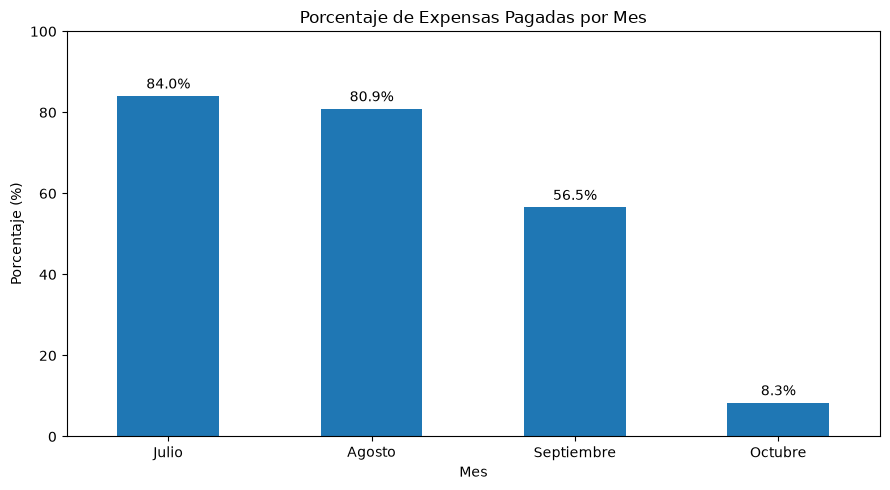

In [40]:
# Asignar los meses
df_apagar_vs_pagado.index = [
    "Julio", "Agosto", "Septiembre", "Octubre"
]

# Calcular el porcentaje pagado
df_apagar_vs_pagado["% PAGADO"] = (
    df_apagar_vs_pagado["PAGADO"]
    .div(df_apagar_vs_pagado["TOTAL A PAGAR"].replace(0, float("nan")))
    .mul(100)
)

# Crear el gráfico
ax = df_apagar_vs_pagado["% PAGADO"].plot(
    kind="bar",
    figsize=(9, 5),
    ylabel="Porcentaje (%)",
    xlabel="Mes",
    title="Porcentaje de Expensas Pagadas por Mes",
    ylim=(0, 100),
    rot=0
)

# Mostrar el porcentaje encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()